In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns

sns.set(style="whitegrid")

In [2]:
df = pd.read_csv('cars.csv')

In [4]:
df.head()

,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [5]:
df.shape

(15411, 14)

In [6]:
df.columns

Index(['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven',
       'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine',
       'max_power', 'seats', 'selling_price'],
      dtype='object')

In [7]:
df.dtypes

Unnamed: 0             int64
car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15411 entries, 0 to 15410
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         15411 non-null  int64  
 1   car_name           15411 non-null  object 
 2   brand              15411 non-null  object 
 3   model              15411 non-null  object 
 4   vehicle_age        15411 non-null  int64  
 5   km_driven          15411 non-null  int64  
 6   seller_type        15411 non-null  object 
 7   fuel_type          15411 non-null  object 
 8   transmission_type  15411 non-null  object 
 9   mileage            15411 non-null  float64
 10  engine             15411 non-null  int64  
 11  max_power          15411 non-null  float64
 12  seats              15411 non-null  int64  
 13  selling_price      15411 non-null  int64  
dtypes: float64(2), int64(6), object(6)
memory usage: 1.6+ MB


In [9]:
df.describe

<bound method NDFrame.describe of        Unnamed: 0         car_name     brand     model  vehicle_age  \
0               0      Maruti Alto    Maruti      Alto            9   
1               1    Hyundai Grand   Hyundai     Grand            5   
2               2      Hyundai i20   Hyundai       i20           11   
3               3      Maruti Alto    Maruti      Alto            9   
4               4    Ford Ecosport      Ford  Ecosport            6   
...           ...              ...       ...       ...          ...   
15406       19537      Hyundai i10   Hyundai       i10            9   
15407       19540    Maruti Ertiga    Maruti    Ertiga            2   
15408       19541      Skoda Rapid     Skoda     Rapid            6   
15409       19542  Mahindra XUV500  Mahindra    XUV500            5   
15410       19543       Honda City     Honda      City            2   

       km_driven seller_type fuel_type transmission_type  mileage  engine  \
0         120000  Individual    Petr

In [10]:
df.isna().sum()

Unnamed: 0           0
car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

In [11]:
df.duplicated().sum()

np.int64(0)

In [13]:
df.drop(columns=['Unnamed: 0'], inplace=True)

In [17]:
df.drop(columns=['car_name'], inplace=True)

In [18]:
df.head()

,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [20]:
df = pd.DataFrame(df)
df.to_csv('cars_cleaned.csv', index=False)

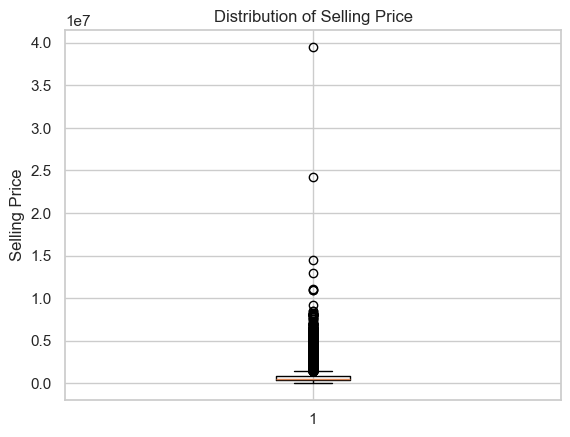

In [31]:
plt.boxplot(df['selling_price'])
plt.title('Distribution of Selling Price')
plt.ylabel('Selling Price')
plt.show()


In [35]:
df["selling_price"].describe(
    percentiles=[ .90, .95, .99]
)

count    1.541100e+04
mean     7.749711e+05
std      8.941284e+05
min      4.000000e+04
50%      5.560000e+05
90%      1.375000e+06
95%      2.050000e+06
99%      4.545000e+06
max      3.950000e+07
Name: selling_price, dtype: float64

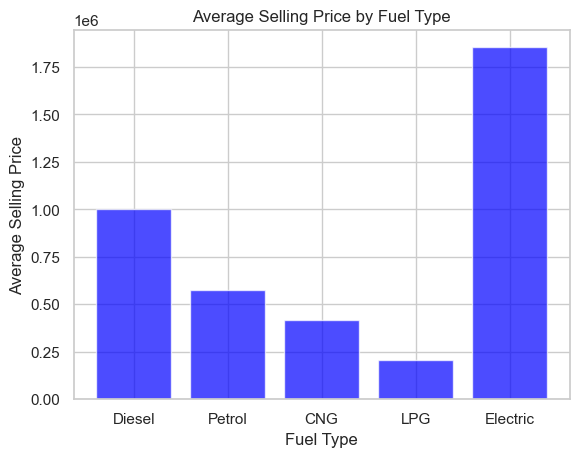

In [38]:
diesel_mean = df[df['fuel_type'] == 'Diesel']['selling_price'].mean()
petrol_mean = df[df['fuel_type'] == 'Petrol']['selling_price'].mean()
CNG_mean = df[df['fuel_type'] == 'CNG']['selling_price'].mean()
LPG_mean = df[df['fuel_type'] == 'LPG']['selling_price'].mean()
Electric_mean = df[df['fuel_type'] == 'Electric']['selling_price'].mean()


plt.bar(['Diesel', 'Petrol', 'CNG', 'LPG', 'Electric'], [diesel_mean, petrol_mean, CNG_mean, LPG_mean, Electric_mean], color='blue', alpha=0.7)
plt.title('Average Selling Price by Fuel Type')
plt.ylabel('Average Selling Price')
plt.xlabel('Fuel Type')
plt.show()


In [39]:
fuel_summary = df.groupby("fuel_type")["selling_price"].agg(
    count="count",
    average="mean",
    median="median"
)

fuel_summary

,count,average,median
fuel_type,,,
CNG,301,4.176877e+05,370000.0
Diesel,7419,1.000469e+06,700000.0
Electric,4,1.853500e+06,1857500.0
LPG,44,2.062727e+05,182500.0
Petrol,7643,5.728619e+05,460000.0


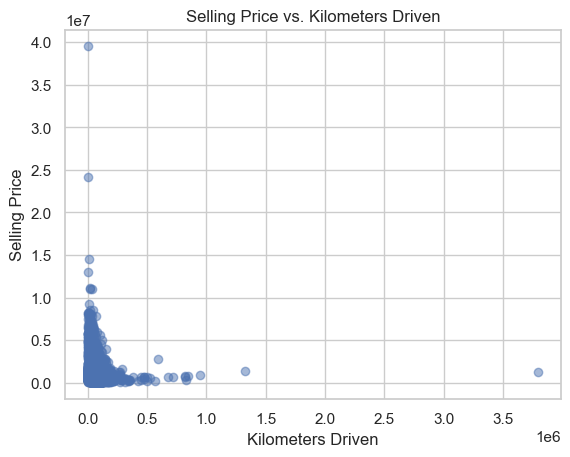

In [40]:
plt.scatter(df['km_driven'], df['selling_price'], alpha=0.5)
plt.title('Selling Price vs. Kilometers Driven')
plt.xlabel('Kilometers Driven')
plt.ylabel('Selling Price')
plt.show()

In [43]:
grouped_by_year = df.groupby("vehicle_age")["selling_price"].agg(
    count="count",
    average="mean",
    median="median"
)
grouped_by_year

,count,average,median
vehicle_age,,,
0,5,2.230000e+06,550000.0
1,221,1.096977e+06,750000.0
2,1145,1.143023e+06,820000.0
3,1926,9.770950e+05,745000.0
4,2252,9.509427e+05,695500.0
5,2117,8.188928e+05,600000.0
6,1924,7.285146e+05,550000.0
7,1438,6.990758e+05,500000.0
8,1282,6.259454e+05,450000.0


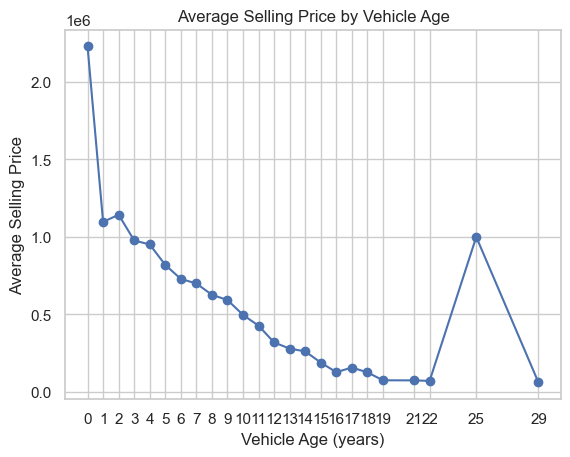

In [44]:
plt.plot(grouped_by_year.index, grouped_by_year['average'], marker='o', linestyle='-')
plt.title('Average Selling Price by Vehicle Age')
plt.xlabel('Vehicle Age (years)')
plt.ylabel('Average Selling Price')
plt.xticks(grouped_by_year.index)
plt.show()

In [46]:
grouped_by_transmission = df.groupby("transmission_type")["selling_price"].agg(
    count="count",
    average="mean",
    median="median"
)
grouped_by_transmission

,count,average,median
transmission_type,,,
Automatic,3186,1.579557e+06,1057000.0
Manual,12225,5.652852e+05,500000.0


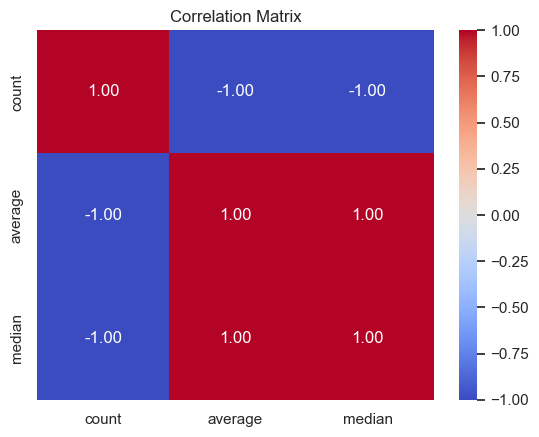

In [50]:
sns.heatmap(grouped_by_transmission.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()


/var/folders/50/6qjzp_fd0kl6stlf_gdl56sr0000gn/T/ipykernel_15707/3597715542.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(x='transmission_type', y='selling_price', data=df, ci=None)


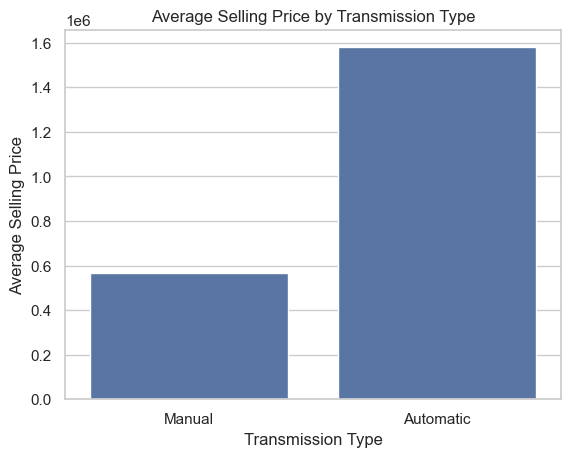

In [54]:
sns.barplot(x='transmission_type', y='selling_price', data=df, ci=None)
plt.title('Average Selling Price by Transmission Type')
plt.xlabel('Transmission Type')
plt.ylabel('Average Selling Price')
plt.grid
plt.show()

## Correlation Analysis

The correlation matrix measures the linear relationships between the selected features and the selling price.

Categorical features such as fuel type and transmission type were converted into numerical dummy variables using one-hot encoding.

Correlation values range from -1 to 1:

- A value close to 1 represents a positive relationship.
- A value close to -1 represents a negative relationship.
- A value close to 0 represents a weak linear relationship.

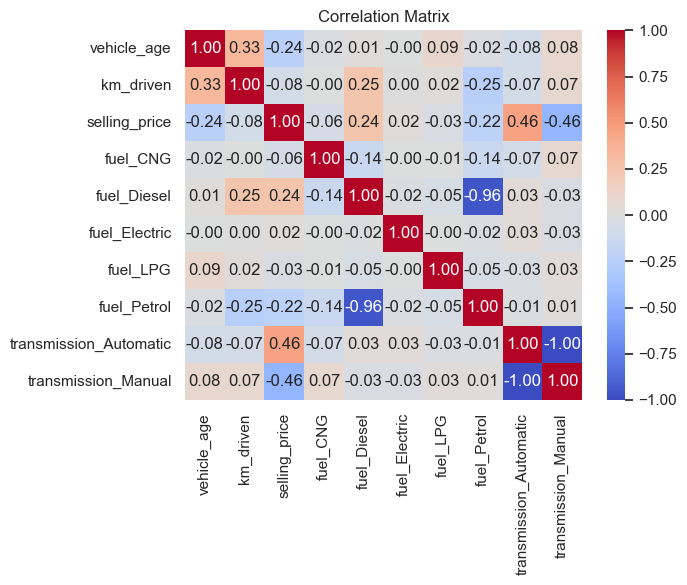

In [57]:
dfinal = ["vehicle_age", "km_driven", "fuel_type", "transmission_type", "selling_price"]

edfinal = pd.get_dummies(df[dfinal], columns=["fuel_type","transmission_type"], prefix=['fuel', 'transmission'], dtype= int)

sns.heatmap(edfinal.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()


### Heatmap Findings

The strongest relationship with selling price is transmission type.

- Automatic transmission has a moderate positive correlation of 0.46 with selling price.
- Manual transmission has a moderate negative correlation of -0.46 with selling price.
- This suggests that automatic cars are generally more expensive than manual cars in this dataset.

Vehicle age has a negative correlation of -0.24 with selling price. This indicates that older vehicles generally have lower selling prices.

Kilometres driven has a weak negative correlation of -0.08 with selling price. Therefore, kilometres driven alone does not strongly explain the selling price.

Diesel vehicles have a positive correlation of 0.24 with selling price, while Petrol vehicles have a negative correlation of -0.22. This suggests that Diesel vehicles are generally more expensive than Petrol vehicles in this dataset.

CNG, LPG, and Electric vehicles show correlations close to zero. However, these results should be interpreted carefully because these fuel categories contain fewer vehicles, especially Electric vehicles.

Vehicle age and kilometres driven have a positive correlation of 0.33. This is reasonable because older vehicles generally have travelled longer distances.

Automatic and Manual transmission have a correlation of -1.00 because they are exact opposite categories. Similarly, the strong negative correlation between Diesel and Petrol is mainly caused by their one-hot encoded representation.

Correlation does not prove causation, and a weak linear correlation does not necessarily mean that a feature will be useless to a machine-learning model.

## EDA Conclusion

The exploratory analysis showed that selling price is affected by vehicle age, transmission type, and fuel type. Automatic and Diesel vehicles are generally associated with higher prices, while older vehicles, Manual vehicles, and Petrol vehicles are associated with lower prices.

The selling-price distribution is strongly right-skewed and contains high-value outliers. These factors will be considered during model evaluation.

The dataset is now ready for preprocessing and baseline model training.

## preprocessing and training ##

In [67]:
df = pd.read_csv('cars_cleaned.csv')
df.head()

,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000


In [68]:
df

,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000
...,...,...,...,...,...,...,...,...,...,...,...,...
15406,Hyundai,i10,9,10723,Dealer,Petrol,Manual,19.81,1086,68.05,5,250000
15407,Maruti,Ertiga,2,18000,Dealer,Petrol,Manual,17.50,1373,91.10,7,925000
15408,Skoda,Rapid,6,67000,Dealer,Diesel,Manual,21.14,1498,103.52,5,425000
15409,Mahindra,XUV500,5,3800000,Dealer,Diesel,Manual,16.00,2179,140.00,7,1225000


In [73]:
features = ["vehicle_age", "km_driven", "fuel_type", "transmission_type", "brand", "model"]

X = df[features].copy()
y = df['selling_price'].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (15411, 6)
Target shape: (15411,)


In [74]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training features shape: (12328, 6)
Testing features shape: (3083, 6)
Training target shape: (12328,)
Testing target shape: (3083,)


In [75]:
numerical_features = ["vehicle_age", "km_driven"]
categorical_features = ["fuel_type", "transmission_type", "brand", "model"]

### Preprocessing Pipeline

Numerical and categorical features require different preprocessing steps.

- Missing numerical values will be replaced with the median.
- Numerical features will be standardized.
- Missing categorical values will be replaced with the most frequent category.
- Categorical features will be converted into numerical values using one-hot encoding.

In [84]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor = ColumnTransformer(transformers=[
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

### Baseline Model: Linear Regression

Linear Regression will be used as the first baseline model. The preprocessing steps and regression model are combined into one pipeline to ensure that the same transformations are applied during training and prediction.

In [85]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_linear = linear_model.predict(X_test)

print("Model training completed.")
print("Number of predictions:", len(y_pred_linear))
print("First five predictions:", y_pred_linear[:5])

Model training completed.
Number of predictions: 3083
First five predictions: [  42573.11749675  635298.77859433  583728.69457266 1223691.05216637
  -55876.98075274]


### Linear Regression Evaluation

The model is evaluated using MAE, RMSE, and R². These metrics compare the predicted selling prices with the real selling prices from the test set.

In [86]:
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

mae = mean_absolute_error(y_test, y_pred_linear)
mse = mean_squared_error(y_test, y_pred_linear)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred_linear)

print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")
print(f"R²: {r2:.4f}")

MAE: 183,026.73
RMSE: 396,738.68
R²: 0.7909


### Linear Regression Results

The Linear Regression model achieved an MAE of 183,086.79, meaning that its predictions differ from the actual selling prices by approximately 183,087 price units on average.

The RMSE was 396,985.32. The large difference between MAE and RMSE indicates that the model makes some particularly large prediction errors, likely because the selling-price distribution contains expensive outliers.

The model achieved an R² score of 0.7906, meaning it explains approximately 79.06% of the variation in selling prices. This represents a strong baseline, although additional features or a non-linear model may improve the predictions.

### Random Forest Model

Random Forest is a non-linear ensemble model that combines predictions from multiple decision trees. It can learn more complex relationships between vehicle characteristics and selling price than Linear Regression.

In [87]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone

random_forest_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

y_pred_forest = random_forest_model.predict(X_test)

print("Random Forest training completed.")
print("Number of predictions:", len(y_pred_forest))

Random Forest training completed.
Number of predictions: 3083


In [88]:
forest_mae = mean_absolute_error(y_test, y_pred_forest)
forest_mse = mean_squared_error(y_test, y_pred_forest)
forest_rmse = np.sqrt(forest_mse)
forest_r2 = r2_score(y_test, y_pred_forest)

print(f"Random Forest MAE: {forest_mae:,.2f}")
print(f"Random Forest RMSE: {forest_rmse:,.2f}")
print(f"Random Forest R²: {forest_r2:.4f}")

Random Forest MAE: 110,675.52
Random Forest RMSE: 271,129.42
Random Forest R²: 0.9023


In [89]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, forest_mae],
    "RMSE": [rmse, forest_rmse],
    "R²": [r2, forest_r2]
})

model_comparison

,Model,MAE,RMSE,R²
0,Linear Regression,183026.727652,396738.679727,0.790907
1,Random Forest,110675.515941,271129.415930,0.902347


In [90]:
forest_train_r2 = random_forest_model.score(X_train, y_train)
forest_test_r2 = random_forest_model.score(X_test, y_test)

print(f"Training R²: {forest_train_r2:.4f}")
print(f"Testing R²: {forest_test_r2:.4f}")

Training R²: 0.9540
Testing R²: 0.9023


### Model Comparison

Random Forest performed significantly better than Linear Regression.

Random Forest reduced the MAE from 183,026.73 to 110,675.52, an improvement of approximately 39.5%. It also reduced the RMSE from 396,738.68 to 271,129.42, indicating fewer large prediction errors.

The R² score increased from 0.7909 to 0.9023. Therefore, Random Forest explains approximately 90.23% of the variation in vehicle selling prices.

The training R² was 0.9540, while the testing R² was 0.9023. This difference indicates mild but acceptable overfitting.

Random Forest was selected as the final model.

### Saving the Final Model

The complete Random Forest pipeline, including preprocessing and the trained model, is saved so it can make future predictions without being trained again.

In [92]:
import joblib

joblib.dump(random_forest_model, "car_price_model.pkl")

print("Model saved successfully.")

Model saved successfully.


In [93]:
loaded_model = joblib.load("car_price_model.pkl")

loaded_predictions = loaded_model.predict(X_test.head(5))

print("Original predictions:")
print(y_pred_forest[:5])

print("\nLoaded model predictions:")
print(loaded_predictions)

print("\nPredictions match:")
print(np.allclose(y_pred_forest[:5], loaded_predictions))

Original predictions:
[ 263126.07142857  660709.16666667  619353.33333333 1289105.
  185276.31944444]

Loaded model predictions:
[ 263126.07142857  660709.16666667  619353.33333333 1289105.
  185276.31944444]

Predictions match:
True


## Predicting the Price of a New Car

The final Random Forest pipeline is used to predict the selling price of a new vehicle. The pipeline automatically applies the same preprocessing used during training.

In [94]:
new_car = pd.DataFrame([{
    "vehicle_age": 5,
    "km_driven": 50000,
    "fuel_type": "Petrol",
    "transmission_type": "Manual",
    "brand": "Maruti",
    "model": "Alto"
}])

predicted_price = random_forest_model.predict(new_car)[0]

print(f"Predicted selling price: {predicted_price:,.2f}")

Predicted selling price: 270,224.14


In [95]:
saved_model = joblib.load("car_price_model.pkl")

predicted_price = saved_model.predict(new_car)[0]

print(f"Predicted selling price: {predicted_price:,.2f}")

Predicted selling price: 270,224.14


### New Car Prediction

The final Random Forest model predicted a selling price of 270,224.14 for a five-year-old Maruti Alto with 50,000 kilometres, Petrol fuel, and Manual transmission.

The model loaded from `car_price_model.pkl` produced the same prediction as the model in the notebook. This confirms that the complete preprocessing and prediction pipeline was saved and loaded successfully.

## Project Conclusion

This project developed a machine-learning model for predicting used-car selling prices.

The dataset was cleaned and explored to understand the effects of vehicle age, kilometres driven, fuel type, transmission type, brand, and model on selling price.

Two regression models were evaluated:

- Linear Regression achieved an R² score of 0.7909.
- Random Forest achieved an R² score of 0.9023.

Random Forest reduced the MAE to 110,675.52 and the RMSE to 271,129.42, significantly outperforming Linear Regression.

The final Random Forest model achieved a training R² of 0.9540 and a testing R² of 0.9023. This indicates mild but acceptable overfitting and strong performance on unseen data.

The complete preprocessing and Random Forest pipeline was saved as `car_price_model.pkl`. The saved model successfully predicted the selling price of a new vehicle.

### Limitations

- Some brands and models have very few observations.
- The selling-price distribution contains expensive outliers.
- Predictions for brands or models not seen during training may be less reliable.
- The model currently uses only six input features.

### Future Improvements

- Add engine, mileage, maximum power, seats, and seller type.
- Tune the Random Forest hyperparameters.
- Apply cross-validation for more reliable evaluation.
- Build a Streamlit interface for entering car information.